# Concept candidates, graded trees and CAV negative pools

One reference year, the historical frozen system. The notebook follows the approved plan, steps 1 to 7:

1. load each build in two modes and check the historical anchors;
2. build candidates from four sources (SAE, cross-seed group score, PCA, random directions) and the matched-count pool;
3. describe each candidate with its rule and a graded tree, scored on reference-year evaluation rows;
4. fit three CAV negative pools (50 bootstrap fits + one declared fit each); the development section (`concept_selection` rows only) comes before the evaluation tables;
5. compare sources with count, capacity and support controls;
6. compare with the historical choices;
7. export the frozen objects and the run record.

All fitting and selection uses reference-year development rows. Evaluation rows are only scored. Every figure is saved as a PNG in `OUTPUT`.

In [1]:
import hashlib, json, os, pickle, resource, subprocess, sys, time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
from IPython.display import display

import cmr_common
import concept_candidates as cc
import concept_subgroup_drift_pilot as pilot
import tcav_geometry as geometry
from concept_study import alternative_bases as ab, loading, paths
from semantic_rules import RuleSet

BUILDS = [("all_history", 2008), ("all_history", 2009), ("all_history", 2010), ("all_history", 2011), ("all_history", 2012),
          ("all_history", 2013), ("last_3", 2010), ("last_3", 2011), ("last_3", 2012), ("last_3", 2013), ("r1", 2007)]
# The 11 builds in patient_table/index.json order.
#   primary, serve last_3: ("all_history", 2008), ("all_history", 2009), ("last_3", 2010) .. ("last_3", 2013), ("r1", 2007)
#   auxiliary, all_history only: ("all_history", 2010) .. ("all_history", 2013)
# Quick check on the pilot build: BUILDS = [("last_3", 2011)] with RUN = "quick_check"
RUN = "full"
OUTPUT = paths.OUTPUT / "extensions" / "concept_candidates" / RUN
FIT_SEEDS = tuple(range(1001, 1051))
SAE_SEEDS = ab.SEEDS
RANDOM_DRAWS, RANDOM_LATENTS, RANDOM_STREAM = ab.RANDOM_DRAWS, ab.RANDOM_LATENTS, 20261110
WORKERS = 24
POOLS = cc.POOLS
FLAGGED = ("last_3/2011/2011/42/42:49,135:91,215:140", "all_history/2009/2009/42/42:233,")
SELECTED_TREES = paths.CODE_ROOT / "analysis_outputs/tree_rule_comparison_20261105/selected-trees.csv"
WORK2_FITS = paths.OUTPUT / "extensions/tcav_geometry/full/per_fit_prediction.csv.gz"
OUTPUT.mkdir(parents=True, exist_ok=True)
STARTED = time.time()
ERRORS, TIMINGS, STATE = [], {}, {}
print("device:", ab.DEVICE, "| cuda available:", torch.cuda.is_available(), "| sklearn", sklearn.__version__)

device: cuda | cuda available: True | sklearn 1.5.2


In [2]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT / f"{name}.png", dpi=120)
    plt.show()


def table(frame, name, show=True):
    frame.to_csv(OUTPUT / f"{name}.csv", index=False)
    if show:
        display(frame)


def usable():
    return [key for key, st in STATE.items() if st.get("ok")]


def fail(key, step, error):
    ERRORS.append({"build": key[0], "reference": key[1], "step": step, "error": f"{type(error).__name__}: {error}"[:400]})
    if key in STATE:
        STATE[key]["ok"] = False
    print("ERROR", key, step, ERRORS[-1]["error"])


def activation(source, rowset, medoid):
    seed, factor = medoid
    return source["codes"][rowset][seed][:, factor]

## Step 1. Load, anchors

Each build is loaded twice: `develop` mode exposes the `rule_discovery`, `cav_fit` and `concept_selection` rows, the default `evaluate` mode exposes the evaluation rows. Roles are rebuilt with the build's split seed and checked against the frozen role identity.

Exact anchors (a failure stops that build's comparisons, not the other builds):
- the SAE path reproduces the frozen families, candidates, rules, cutoffs and A/R masks;
- the legacy and eligible refits reproduce the saved directions of every concept (rtol 1e-4, atol 1e-5, same failed fits).

Descriptive anchors (tree selections, saved selection AUROCs) are shown in steps 4 and 6, where the new trees and fits exist.

The Work 0 ledger has no tuned-threshold column, so the descriptive anchor of the new tuned thresholds against it is unavailable; the new thresholds are listed beside `selected-trees.csv` in step 6.

In [3]:
inputs = loading.open_inputs()
population = inputs["population"]
index = json.load(open(paths.PATIENT_TABLE / "index.json"))
PANEL = {(r["build"], r["reference"]): "primary" if "last_3" in r["variants"] else "auxiliary" for r in index["builds"]}
saved_directions, _ = loading.load_cav_directions()
with open(paths.CAV_FREEZE, "rb") as handle:
    freeze_units = pickle.load(handle)["payload"]["units"]

anchor_rows, replay_rows = [], []
for build, reference in BUILDS:
    key, started = (build, reference), time.time()
    try:
        STATE[key] = st = {"ok": False, "panel": PANEL[key]}
        record = next(r for r in index["builds"] if (r["build"], r["reference"]) == key)
        items = [i for i in inputs["inventory"] if (i["build"], i["reference"]) == key]
        frozen_roles, cache = items[0]["roles"], inputs["caches"][build]
        split = cc.reference_roles(population, cache, reference, frozen_roles)
        bases = cc.load_build_two_modes(inputs, build, reference, frozen_roles)
        dev, ev = bases["develop"], bases["evaluate"]
        data = ab.reference_data(inputs, record)

        at = lambda base, role: np.flatnonzero((base["years"] == reference) & (base["roles"] == role))
        rows = {"cav_fit": at(dev, "cav_fit"), "selection": at(dev, "concept_selection"), "rule": at(dev, "rule_discovery"),
                "evaluation": at(ev, "evaluation")}
        all_evaluation = np.flatnonzero(ev["roles"] == "evaluation")
        ref_eval = data["table"]["year"] == reference
        assert np.array_equal(ev["patients"][all_evaluation], data["table"]["patient_id"].astype(str))
        assert np.array_equal(ev["years"][all_evaluation], data["table"]["year"])
        assert np.array_equal(all_evaluation[ref_eval], rows["evaluation"])
        assert np.allclose(ev["embeddings"][all_evaluation], data["eval_emb"])

        role, year, entrant = split["row_role"], population["year"], split["is_entrant"]
        cc.check_fit_rows(data["families"]["row_index"], role, year, entrant, reference, ("rule_discovery", "cav_fit"))
        cc.check_fit_rows(dev["row_index"][rows["cav_fit"]], role, year, entrant, reference, ("cav_fit",))
        cc.check_fit_rows(dev["row_index"][rows["rule"]], role, year, entrant, reference, ("rule_discovery",))
        _, archive, archive_rows = cmr_common.verified_predictor_archive(population, cache, reference, frozen_roles)
        chosen = archive_rows[(year[archive_rows] == reference) & (role[archive_rows] == "sae_discovery") & ~entrant[archive_rows]]
        assert len(chosen) == len(data["fit_z"])
        cc.check_fit_rows(chosen, role, year, entrant, reference, ("sae_discovery",))

        anchor, sae_concepts, sae_summary, sae_sweep = cc.sae_rule_anchor(data, index)
        replay_names, replay_candidates, replay_saved, replay_x, skipped = [], [], [], None, 0
        for item in items:
            name = loading.concept_key(build, reference, item["family"])
            if ("legacy", name) not in saved_directions or ("all_negatives", name) not in saved_directions:
                skipped += 1
                continue
            unit = loading.concept_unit(bases["develop_inputs"], dev, item)
            at_fit = unit["cav_fit"]
            replay_x = unit["embeddings"][at_fit]
            replay_names.append(name)
            replay_candidates.append({"rule": unit["rule_mask"][at_fit], "activation": unit["activation"][at_fit], "patients": unit["patients"][at_fit]})
            replay_saved.append({"legacy": saved_directions[("legacy", name)], "eligible": saved_directions[("all_negatives", name)]})
        replays = cc.replay_concepts(replay_x, replay_candidates, replay_saved, FIT_SEEDS, WORKERS) if replay_candidates else []
        for name, replay in zip(replay_names, replays):
            replay_rows += [{"build": build, "reference": reference, "concept": name, "pool": pool, **r} for pool, r in replay.items()]
        ok = cc.anchors_pass(anchor, replays)
        st.update(record=record, items=items, frozen_roles=frozen_roles, split=split, bases=bases, data=data, rows=rows,
                  ref_eval=ref_eval, anchor=anchor, sae_concepts=sae_concepts, sae_summary=sae_summary, sae_sweep=sae_sweep,
                  ok=ok, split_seed=cache.config["split_seed"])
        anchor_rows.append({"build": build, "reference": reference, "panel": st["panel"], **anchor,
                            "concepts_replayed": len(replays), "concepts_without_saved_directions": skipped,
                            "replay_failures": sum(not r["passed"] for rep in replays for r in rep.values()),
                            "replay_max_abs_gap": max([r["max_abs_gap"] for rep in replays for r in rep.values()] or [np.nan]),
                            "exact_anchors_hold": ok})
        print(key, {k: len(v) for k, v in rows.items()}, "anchors hold:", ok, f"{time.time() - started:.0f}s")
    except Exception as error:
        fail(key, "1 load and anchors", error)
    TIMINGS[f"1 {build} {reference}"] = time.time() - started

anchors_df = pd.DataFrame(anchor_rows)
table(anchors_df, "anchors_exact")
table(pd.DataFrame(replay_rows), "anchors_replay_by_concept", show=False)

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


('all_history', 2008) {'cav_fit': 150, 'selection': 149, 'rule': 299, 'evaluation': 298} anchors hold: True 29s


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


('all_history', 2009) {'cav_fit': 156, 'selection': 154, 'rule': 310, 'evaluation': 310} anchors hold: True 43s


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


('all_history', 2010) {'cav_fit': 163, 'selection': 161, 'rule': 324, 'evaluation': 324} anchors hold: True 46s


... (11 outputs left out)

('last_3', 2013) {'cav_fit': 161, 'selection': 161, 'rule': 322, 'evaluation': 322} anchors hold: True 54s


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


('r1', 2007) {'cav_fit': 119, 'selection': 118, 'rule': 237, 'evaluation': 237} anchors hold: True 38s


,build,reference,panel,family_counts_equal,candidates_equal,frozen_rules,frozen_rules_cached,rule_identities_equal,concepts_missing_from_index,A_or_R_row_mismatches,agreement_max_abs_gap,index_concepts,concepts_replayed,concepts_without_saved_directions,replay_failures,replay_max_abs_gap,exact_anchors_hold
0,all_history,2008,primary,True,True,6,6,True,0,0,0.0,6,6,0,0,1.488596e-08,True
1,all_history,2009,primary,True,True,10,10,True,0,0,0.0,10,10,0,0,1.489340e-08,True
2,all_history,2010,auxiliary,True,True,8,8,True,0,0,0.0,8,8,0,0,1.489587e-08,True
3,all_history,2011,auxiliary,True,True,7,7,True,0,0,0.0,7,5,2,0,1.489451e-08,True
4,all_history,2012,auxiliary,True,True,11,11,True,0,0,0.0,11,11,0,0,1.487528e-08,True
5,all_history,2013,auxiliary,True,True,7,7,True,0,0,0.0,7,7,0,0,1.489464e-08,True
6,last_3,2010,primary,True,True,7,7,True,0,0,0.0,7,7,0,0,1.490066e-08,True
7,last_3,2011,primary,True,True,14,14,True,0,0,0.0,14,14,0,0,1.488595e-08,True
8,last_3,2012,primary,True,True,7,7,True,0,0,0.0,7,6,1,0,1.489128e-08,True
9,last_3,2013,primary,True,True,14,14,True,0,0,0.0,14,14,0,0,1.489521e-08,True


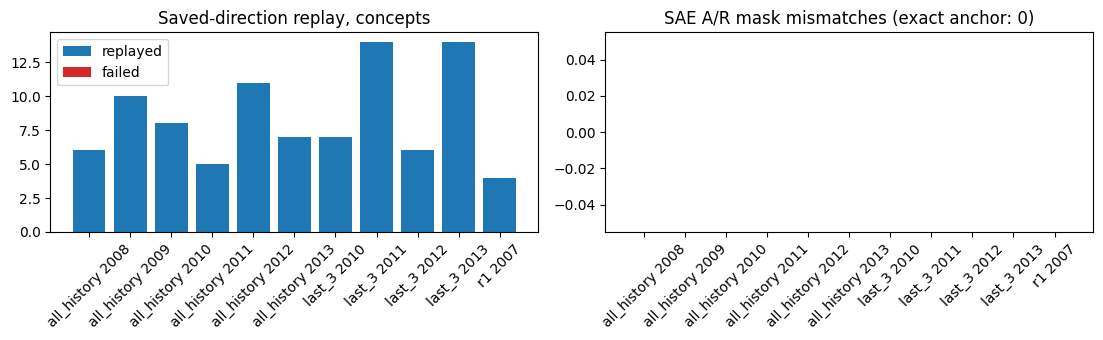

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
if len(anchors_df):
    labels = [f"{b} {r}" for b, r in zip(anchors_df.build, anchors_df.reference)]
    axes[0].bar(labels, anchors_df.concepts_replayed, label="replayed")
    axes[0].bar(labels, anchors_df.replay_failures, label="failed", color="C3")
    axes[0].set_title("Saved-direction replay, concepts"); axes[0].legend()
    axes[1].bar(labels, anchors_df.A_or_R_row_mismatches, color="C1")
    axes[1].set_title("SAE A/R mask mismatches (exact anchor: 0)")
    for ax in axes: ax.tick_params(axis="x", rotation=45)
save(fig, "step1_anchors")

## Step 2. Candidates

Sources, all on the same reference rows (SAE training rows `sae_discovery` for scales and PCA; matching rows `rule_discovery` + `cav_fit` for ranking and member checks):
- **sae**: frozen full-family medoids, capped at `candidate_cap(288, 0.1)`; its candidate count is the cap of every other source and of the pool;
- **group**: each full family's members divided by their SD on `sae_discovery` rows, then averaged (SD-0 members left out and counted; no usable member, no score);
- **pca**: ReLU(+score) and ReLU(-score) of the leading components fitted on `sae_discovery` rows;
- **random1 .. random5**: ReLU of 288 random unit directions per SAE seed, a control; each draw is its own source and is never pooled;
- **pool**: SAE + group + PCA candidates ranked by positive count on the matching rows, capped at the SAE candidate count. A pool member is the same score as its source candidate, so it takes that source's rule, cutoff, masks and inner split from the source's own sweep; the sweep treats each candidate alone, so nothing is re-swept.

In [5]:
candidate_rows = []
for key in usable():
    st, (build, reference), started = STATE[key], key, time.time()
    try:
        data, bases, rows, cache = st["data"], st["bases"], st["rows"], inputs["caches"][build]
        dev, ev = bases["develop"], bases["evaluate"]
        prefix = f"{reference}/{st['split_seed']}"
        enc = ab.sae_encoders(data)
        cap_sae = pilot.candidate_cap(RANDOM_LATENTS, cache.config["candidate_cap_fraction"])
        match = {s: e(data["match_emb"]) for s, e in enc.items()}
        _, sae_candidates = ab.family_candidates(match, prefix, cap_sae)
        cap = len(sae_candidates)
        families = pilot.build_factor_families([match[s] for s in SAE_SEEDS], list(SAE_SEEDS), device=ab.DEVICE, id_prefix=prefix)["families"]
        members = cc.family_members(families)

        fit_raw = data["scaler"].inverse_transform(data["fit_z"]).astype(np.float32)
        fit_codes = {s: enc[s](fit_raw) for s in enc}
        group_all, group_info, group_dropped = cc.group_encoder(enc, fit_codes, members)
        keep = cc.top_columns(group_all(data["match_emb"]), cap)
        group_factor = cc.columns_encoder({"group": group_all}, [("group", int(j)) for j in keep])
        group_ids = [group_info[j]["id"] for j in keep]
        group_by_id = {i["id"]: i for i in group_info}

        sae_factor = cc.columns_encoder({f"s{s}": enc[s] for s in enc}, [(f"s{c['medoid'][0]}", c["medoid"][1]) for c in sae_candidates])
        sae_ids = [c["family_id"] for c in sae_candidates]
        pca_factor = ab.on_raw(cc.pca_candidates(data["fit_z"], cap), data)
        pca_ids = [f"pca/{prefix}/{j // 2 + 1}{'+-'[j % 2]}" for j in range(cap)]

        cc.attach_sweep(st["sae_concepts"], st["sae_sweep"])
        sources = [{"name": "sae", "draw": 0, "encoders": enc, "concepts": st["sae_concepts"], "candidates": sae_candidates}]
        for name, factor, ids in (("group", group_factor, group_ids), ("pca", pca_factor, pca_ids)):
            concepts, candidates, _ = cc.factor_concepts(name, 0, data, factor, ids)
            sources.append({"name": name, "draw": 0, "encoders": {0: factor}, "concepts": concepts, "candidates": candidates})
        for draw in range(1, RANDOM_DRAWS + 1):
            encoders = {s: ab.on_raw(ab.random_encoder(data["fit_z"].shape[1], RANDOM_LATENTS, [RANDOM_STREAM, reference, draw, s]), data)
                        for s in SAE_SEEDS}
            pre = f"random{draw}/{prefix}"
            concepts, _, sweep = ab.basis_concepts("random", draw, data, encoders, cap, pre)
            cc.attach_sweep(concepts, sweep)
            _, candidates = ab.family_candidates({s: e(data["match_emb"]) for s, e in encoders.items()}, pre, cap)
            sources.append({"name": f"random{draw}", "draw": draw, "encoders": encoders, "concepts": concepts, "candidates": candidates})

        factors = {"sae": (sae_factor, sae_ids), "group": (group_factor, group_ids), "pca": (pca_factor, pca_ids)}
        meta = []
        for name, (factor, ids) in factors.items():
            matrix = factor(data["match_emb"])
            meta += [{"source": name, "id": ids[j], "column": j, "positive_count": int((matrix[:, j] > 0).sum())} for j in range(matrix.shape[1])]
        pool_meta = cc.matched_count_pool(meta, cap)
        pool_factor = cc.columns_encoder({n: f for n, (f, _) in factors.items()}, [(m["source"], m["column"]) for m in pool_meta])
        pool_ids = [f"{m['source']}:{m['id']}" for m in pool_meta]
        concepts, candidates = cc.pool_concepts(pool_meta, {s["name"]: {c["family_id"]: c for c in s["concepts"]} for s in sources})
        sources.append({"name": "pool", "draw": 0, "encoders": {0: pool_factor}, "concepts": concepts, "candidates": candidates,
                        "origin": dict(zip(pool_ids, pool_meta))})

        sets_emb = {"match": data["match_emb"], "cav_fit": dev["embeddings"][rows["cav_fit"]],
                    "selection": dev["embeddings"][rows["selection"]], "evaluation": ev["embeddings"][rows["evaluation"]]}
        patients = {"match": data["match_patients"], "cav_fit": dev["patients"][rows["cav_fit"]],
                    "selection": dev["patients"][rows["selection"]], "evaluation": ev["patients"][rows["evaluation"]]}
        for src in sources:
            src["codes"] = {name: {k: e(emb) for k, e in src["encoders"].items()} for name, emb in sets_emb.items()}
            with_rule = {c["family_id"] for c in src["concepts"]}
            for candidate in src["candidates"]:
                fid, medoid = candidate["family_id"], candidate["medoid"]
                acts = {name: activation(src, name, medoid) for name in sets_emb}
                checks, scale = {}, "standardized"
                if src["name"] == "sae":
                    definition, orientation = {"family_id": fid, "members": json.dumps(members[fid])}, "ReLU(+)"
                elif src["name"] == "group":
                    info = group_by_id[fid]
                    mc = cc.member_correlations(np.stack([match[s][:, f] for s, f in info["members"]], 1), acts["match"], info["used"])
                    definition, orientation = {"family_id": fid, "members": json.dumps(info["members"])}, "mean of scaled members"
                    scale = json.dumps([float(x) for x in info["scale"]])
                    checks = {"members_left_out": info["left_out"], "corr_with_score_min": float(np.min(mc["with_score"])),
                              "corr_with_score_median": float(np.median(mc["with_score"])),
                              "corr_between_min": float(np.min(mc["between"])),
                              "members_negative_with_score": json.dumps(mc["negative_with_score"]),
                              "pairs_negative": json.dumps(mc["negative_pairs"])}
                elif src["name"] == "pca":
                    j = pca_ids.index(fid)
                    definition, orientation = {"family_id": fid, "pc": j // 2 + 1, "sign": "+-"[j % 2]}, "ReLU(" + "+-"[j % 2] + "score)"
                elif src["name"] == "pool":
                    origin = src["origin"][fid]
                    definition, orientation = {"family_id": fid, "origin_source": origin["source"], "origin_id": origin["id"]}, "as origin"
                else:
                    definition, orientation = {"family_id": fid, "medoid": json.dumps(medoid)}, "ReLU(random unit direction)"
                row = cc.candidate_row(build, reference, src["name"], medoid[0] if src["name"] == "sae" or src["name"].startswith("random") else None,
                                       src["draw"], definition, scale, orientation, acts, patients, checks)
                candidate_rows.append({**row, "panel": st["panel"], "rank": candidate["rank"], "positive_count_match": candidate["positive_count"],
                                       "cap": cap, "has_rule": fid in with_rule, "group_families_dropped": len(group_dropped)})
        st.update(sources=sources, members=members, group_info=group_info, group_dropped=group_dropped, cap=cap, pool_meta=pool_meta,
                  prefix=prefix, patients=patients)
        print(key, "cap", cap, {s["name"]: (len(s["candidates"]), len(s["concepts"])) for s in sources},
              "group families without a usable member:", len(group_dropped), f"{time.time() - started:.0f}s")
    except Exception as error:
        fail(key, "2 candidates", error)
    TIMINGS[f"2 {build} {reference}"] = time.time() - started

candidates_df = pd.DataFrame(candidate_rows)
table(candidates_df.drop(columns=["members", "scale"], errors="ignore").head(30), "candidates_preview")
table(candidates_df, "candidates", show=False)
table(candidates_df[candidates_df.source == "group"], "group_score_member_checks", show=False)

/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


('all_history', 2008) cap 9 {'sae': (9, 6), 'group': (9, 6), 'pca': (9, 8), 'random1': (8, 6), 'random2': (9, 7), 'random3': (8, 4), 'random4': (9, 6), 'random5': (6, 5), 'pool': (9, 8)} group families without a usable member: 0 236s


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


/home/rafaelgomes/SAE-TCAV/.venv/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


... (10 outputs left out)

('last_3', 2012) cap 14 {'sae': (14, 7), 'group': (14, 12), 'pca': (14, 10), 'random1': (9, 7), 'random2': (12, 9), 'random3': (11, 7), 'random4': (10, 9), 'random5': (7, 6), 'pool': (14, 9)} group families without a usable member: 0 348s


('last_3', 2013) cap 14 {'sae': (14, 14), 'group': (14, 9), 'pca': (14, 8), 'random1': (12, 9), 'random2': (8, 3), 'random3': (8, 6), 'random4': (6, 4), 'random5': (6, 4), 'pool': (14, 6)} group families without a usable member: 0 311s


('r1', 2007) cap 10 {'sae': (10, 4), 'group': (10, 5), 'pca': (10, 5), 'random1': (10, 7), 'random2': (10, 6), 'random3': (8, 3), 'random4': (10, 6), 'random5': (7, 2), 'pool': (10, 5)} group families without a usable member: 0 282s


,build,reference,source,seed,draw,family_id,orientation,positive_rows_match,positive_patients_match,positive_rows_cav_fit,...,corr_with_score_min,corr_with_score_median,corr_between_min,members_negative_with_score,pairs_negative,pc,sign,medoid,origin_source,origin_id
0,all_history,2008,sae,42.0,0,"2008/42/42:283,135:131,215:29",ReLU(+),241,241,80,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,all_history,2008,sae,42.0,0,"2008/42/42:279,135:190,215:167",ReLU(+),227,227,66,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,all_history,2008,sae,135.0,0,"2008/42/42:187,135:255,215:20",ReLU(+),214,214,68,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,all_history,2008,sae,215.0,0,"2008/42/42:0,135:24,215:233",ReLU(+),213,213,76,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,all_history,2008,sae,215.0,0,"2008/42/42:80,135:92,215:154",ReLU(+),201,201,65,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,all_history,2008,sae,135.0,0,"2008/42/42:57,135:159,215:175",ReLU(+),183,183,72,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,all_history,2008,sae,42.0,0,"2008/42/42:218,135:228,215:236",ReLU(+),178,178,70,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,all_history,2008,sae,215.0,0,"2008/42/42:4,135:182,215:195",ReLU(+),172,172,69,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,all_history,2008,sae,215.0,0,"2008/42/42:142,135:265,215:184",ReLU(+),164,164,52,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,all_history,2008,group,NaN,0,"2008/42/42:279,135:190,215:167",mean of scaled members,284,284,87,...,0.981938,0.983215,0.940880,[],[],NaN,NaN,NaN,NaN,NaN


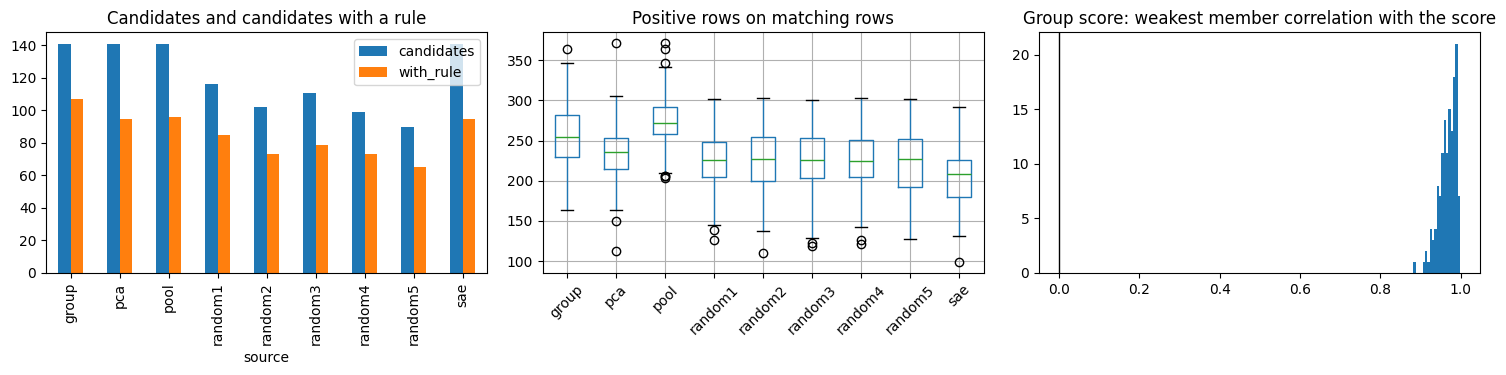

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
yield_counts = candidates_df.groupby("source").agg(candidates=("family_id", "size"), with_rule=("has_rule", "sum"))
yield_counts.plot.bar(ax=axes[0]); axes[0].set_title("Candidates and candidates with a rule")
candidates_df.boxplot(column="positive_count_match", by="source", ax=axes[1], rot=45)
axes[1].set_title("Positive rows on matching rows"); axes[1].set_xlabel("")
groups = candidates_df[candidates_df.source == "group"]
if len(groups):
    axes[2].hist(groups.corr_with_score_min.dropna(), bins=20)
    axes[2].axvline(0, color="k", lw=1)
    axes[2].set_title("Group score: weakest member correlation with the score")
plt.suptitle("")
save(fig, "step2_candidates")

## Step 3. Descriptions

Each candidate gets two descriptions on the same development rows:
- the **rule** from the frozen semantic sweep (`rule_discovery` rows, patient 50/50 fit/tune split);
- a **graded tree** on the candidate's continuous score from the 500 count features, on the same split (3/5/8 leaves, tune MAE, ties to fewer leaves), next to constant-median, ridge and boosting benchmarks.

Both are scored on reference-year evaluation rows: rule F1/F2 against A (activation above the cutoff), tree MAE (all rows and A rows), retained reduction, and the tree as a binary detector of A at the original cutoff and at a threshold tuned on the tune rows. Unsupported and undefined cases stay in the table. Intervals (500 patient draws, seeds 3001-3500, paired across rule and tree) are given for rule F1, tree F1, their difference and retained reduction only.

In [7]:
description_rows, interval_rows, PANELS = [], [], {}
for key in usable():
    st, (build, reference), started = STATE[key], key, time.time()
    try:
        data, ref_eval = st["data"], st["ref_eval"]
        ids = np.asarray(pilot._canonical_patient_ids(data["rule_patients"]))
        X_eval = data["X_eval"][ref_eval]
        weights = cc.patient_weights(st["patients"]["evaluation"], cc.BOOTSTRAP_SEEDS)
        for src in st["sources"]:
            for c in src["concepts"]:
                y_rule = activation(src, "match", c["medoid"])[data["rule_pos"]]
                y_eval = activation(src, "evaluation", c["medoid"])
                assert len(y_eval) == len(X_eval)
                fit_ids, tune_ids = pilot.rule_inner_split(ids, y_rule, c["inner_split"]["seed"])
                fit, tune = np.isin(ids, fit_ids), np.isin(ids, tune_ids)
                in_R = c["in_R"][ref_eval]
                row, panel = cc.describe_candidate(data["X_rule"][fit], y_rule[fit], data["X_rule"][tune], y_rule[tune],
                                                   X_eval, y_eval, c["cutoff"], in_R)
                base = {"build": build, "reference": reference, "panel": st["panel"], "source": src["name"], "concept": c["concept"],
                        "family_id": c["family_id"], "cutoff": c["cutoff"], "rule_conditions": c["condition_count"],
                        "rule_count": c["rule_count"], "sweep_tune_f2": c["tune_f2"], "n_eval_rows": len(y_eval),
                        "n_A_eval": int((y_eval > c["cutoff"]).sum()),
                        "split_equals_sweep": bool(fit.sum() == c["inner_split"]["fit_rows"] and tune.sum() == c["inner_split"]["tune_rows"])}
                description_rows.append({**base, **row})
                if panel is not None:
                    PANELS[c["concept"]] = {"panel": panel, "feature_names": data["feature_names"], "source": src["name"], "build": build}
                    models = panel["models"]
                    iv = cc.fidelity_intervals(weights, y_eval, models["tree"].predict(X_eval), models["constant"].predict(X_eval),
                                               models["boosting"].predict(X_eval), y_eval > c["cutoff"], in_R, c["cutoff"])
                    interval_rows.append({**base, **{f"{q}_{k}": v for q, d in iv.items() for k, v in d.items()}})
        print(key, "descriptions:", sum(r["build"] == build and r["reference"] == reference for r in description_rows), f"{time.time() - started:.0f}s")
    except Exception as error:
        fail(key, "3 descriptions", error)
    TIMINGS[f"3 {build} {reference}"] = time.time() - started

desc_df, intervals_df = pd.DataFrame(description_rows), pd.DataFrame(interval_rows)
table(desc_df.groupby("source").agg(candidates=("concept", "size"), measured=("status", lambda s: (s == "measured").sum()),
                                    split_equals_sweep=("split_equals_sweep", "all"),
                                    median_rule_f1=("rule_f1", "median"), median_tree_f1_cutoff=("tree_f1_cutoff", "median"),
                                    median_retained_reduction=("retained_reduction", "median"),
                                    undefined_retained_reduction=("retained_reduction", lambda s: int(s.isna().sum())),
                                    no_tuned_threshold=("threshold_status", lambda s: int((s == "none").sum()))).reset_index(),
      "descriptions_by_source")
table(desc_df, "descriptions", show=False)
table(intervals_df, "description_intervals", show=False)

('all_history', 2008) descriptions: 56 8s


('all_history', 2009) descriptions: 81 13s


('all_history', 2010) descriptions: 84 13s


('all_history', 2011) descriptions: 63 9s


('all_history', 2012) descriptions: 84 13s


('all_history', 2013) descriptions: 67 11s


... (2 outputs left out)

('last_3', 2012) descriptions: 76 11s


('last_3', 2013) descriptions: 63 10s


('r1', 2007) descriptions: 43 6s


,source,candidates,measured,split_equals_sweep,median_rule_f1,median_tree_f1_cutoff,median_retained_reduction,undefined_retained_reduction,no_tuned_threshold
0,group,107,107,True,0.760563,0.701149,0.785976,1,32
1,pca,95,95,True,0.666667,0.472727,0.752898,1,39
2,pool,96,96,True,0.670175,0.644958,0.753851,1,26
3,random1,85,85,True,0.658228,0.520231,0.823942,0,37
4,random2,73,73,True,0.714286,0.673684,0.835765,0,24
5,random3,79,79,True,0.679245,0.561798,0.815061,2,24
6,random4,73,73,True,0.610169,0.597015,0.843373,1,24
7,random5,65,65,True,0.716981,0.616541,0.839503,0,21
8,sae,95,95,True,0.700000,0.631068,0.802329,1,37


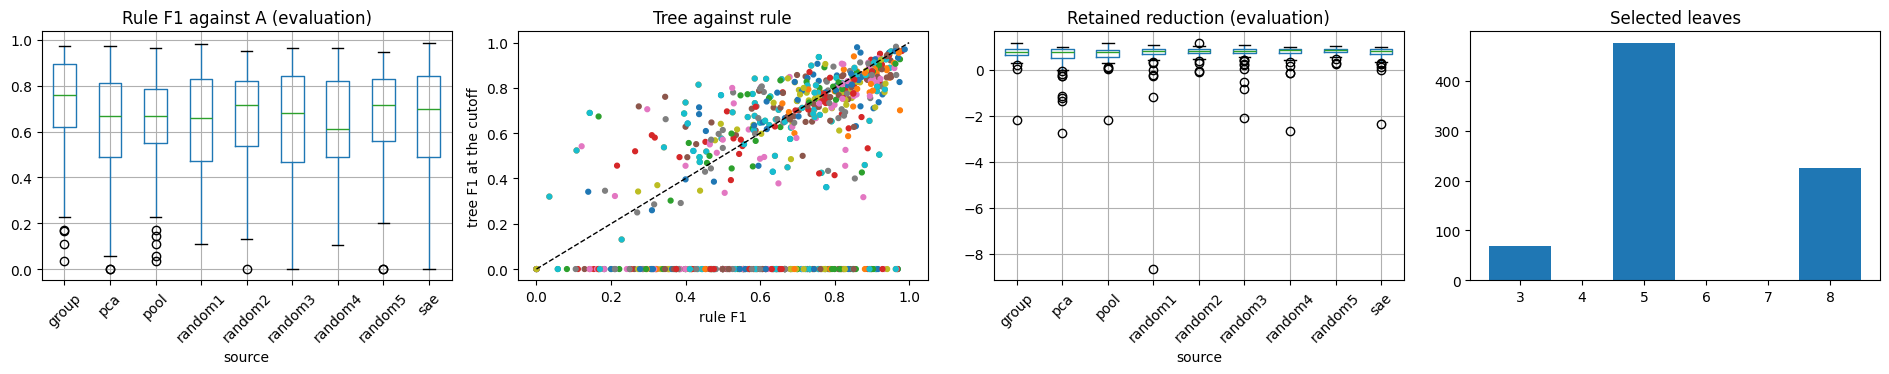

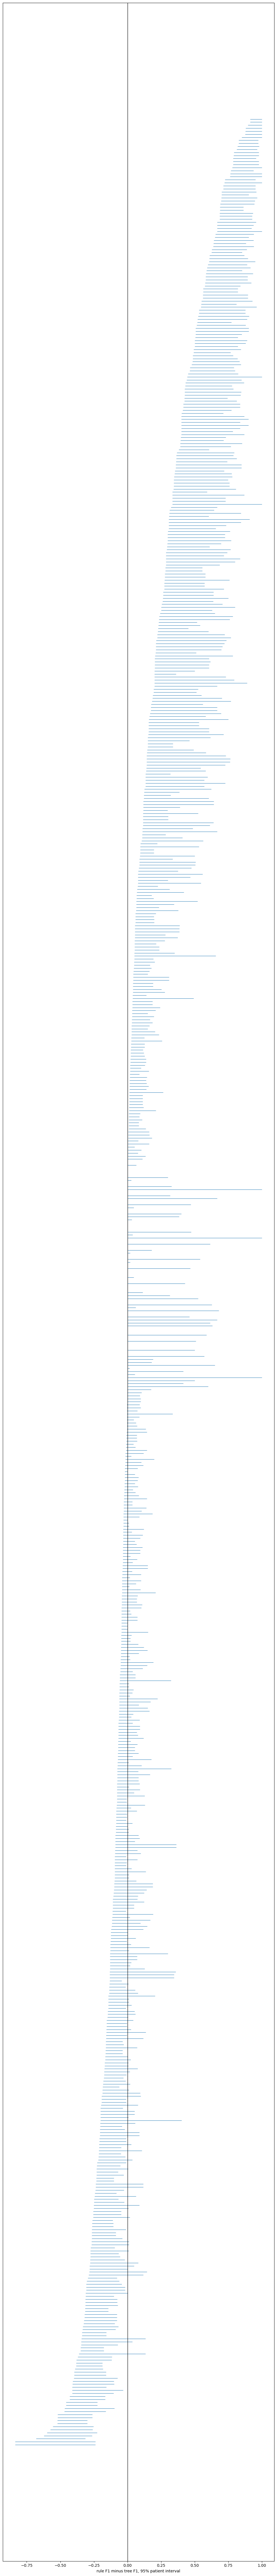

In [8]:
measured = desc_df[desc_df.status == "measured"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
measured.boxplot(column="rule_f1", by="source", ax=axes[0], rot=45); axes[0].set_title("Rule F1 against A (evaluation)")
axes[1].scatter(measured.rule_f1, measured.tree_f1_cutoff, s=12, c=pd.factorize(measured.source)[0], cmap="tab10")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("rule F1"); axes[1].set_ylabel("tree F1 at the cutoff"); axes[1].set_title("Tree against rule")
measured.boxplot(column="retained_reduction", by="source", ax=axes[2], rot=45); axes[2].set_title("Retained reduction (evaluation)")
axes[3].hist(measured.leaves, bins=[2.5, 3.5, 4.5, 5.5, 7.5, 8.5]); axes[3].set_title("Selected leaves")
plt.suptitle("")
save(fig, "step3_fidelity")

if len(intervals_df):
    order = intervals_df.sort_values("f1_difference_low").reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(10, max(3, 0.12 * len(order))))
    mid = (order.f1_difference_low + order.f1_difference_high) / 2
    ax.errorbar(mid, range(len(order)), xerr=[mid - order.f1_difference_low, order.f1_difference_high - mid], fmt="none", lw=0.8)
    ax.axvline(0, color="k", lw=1); ax.set_xlabel("rule F1 minus tree F1, 95% patient interval"); ax.set_yticks([])
    save(fig, "step3_rule_minus_tree_f1")

## Step 4. CAV negative pools

For every candidate with a rule, three pools on the same target (rule membership) and the same `cav_fit` rows, with raw embeddings, C = 0.1 and equal class mass:
- **legacy**: the historical balanced subsample of minimum-activation negatives;
- **eligible**: every minimum-activation negative (historical "all negatives");
- **literal**: every rule-negative `cav_fit` row.

50 bootstrap fits (seeds 1001-1050) plus one declared fit (every row once) per pool. Positive draws are shared across pools for each seed; the literal negatives come from their own stream. Each fit is scored on two populations (all rule-labelled rows; the restricted stratum of positives and minimum-activation negatives), on evaluation and on `concept_selection` rows, with the boundary angle to the mean unit log-odds gradient, fit-to-fit cosines and the mean log-odds sensitivity on R rows. No pool is declared a winner.

The development section (`concept_selection` rows only) is shown first; the evaluation tables follow.

The liblinear fits of a build run in one joblib call (24 workers, one BLAS thread each). The readouts over fits (AUROC on both populations and both row sets, angles, cosines, sensitivity) and the 500-draw patient bootstrap run in batched torch on cuda, with batches sized to at most half of the free GPU memory; free memory, batch sizes and peak allocation per build go into `run.json`.

In [9]:
fit_rows, declared_rows, cosine_rows, population_rows, join_rows = [], [], [], [], []
CLASSIFIERS, DECLARED_DRAWS = {}, {}
GPU_LOG = {}
for key in usable():
    st, (build, reference), started = STATE[key], key, time.time()
    cuda = torch.cuda.is_available()
    if cuda:
        torch.cuda.reset_peak_memory_stats()
    free_before = torch.cuda.mem_get_info()[0] if cuda else None
    cc.BATCH_LOG.clear()
    try:
        dev, ev, rows = st["bases"]["develop"], st["bases"]["evaluate"], st["rows"]
        cav, sel, evl = rows["cav_fit"], rows["selection"], rows["evaluation"]
        selection_gradients = geometry.log_odds_gradients(dev["gradients"][sel], dev["probabilities"][sel, 1])
        evaluation_gradients = geometry.log_odds_gradients(ev["gradients"][evl], ev["probabilities"][evl, 1])
        weights = cc.patient_weights(ev["patients"][evl], cc.BOOTSTRAP_SEEDS)
        entries = []
        for src in st["sources"]:
            for c in src["concepts"]:
                rule = RuleSet.from_dict(c["rule_dict"])
                act = lambda name: activation(src, name, c["medoid"])
                evaluation_rule = c["in_R"][st["ref_eval"]]
                sets = {"evaluation": {"X": ev["embeddings"][evl], "rule": evaluation_rule, "activation": act("evaluation"),
                                       "patients": ev["patients"][evl], "gradients": evaluation_gradients},
                        "selection": {"X": dev["embeddings"][sel], "rule": rule.mask(dev["X"][sel]), "activation": act("selection"),
                                      "patients": dev["patients"][sel], "gradients": selection_gradients}}
                entries.append({"c": c, "src": src["name"], "sets": sets, "evaluation_rule": evaluation_rule,
                                "fit": {"rule": rule.mask(dev["X"][cav]), "activation": act("cav_fit"), "patients": dev["patients"][cav]}})
        X_fit = dev["embeddings"][cav]
        fitted = cc.fit_candidates(X_fit, [e["fit"] for e in entries], FIT_SEEDS, WORKERS)
        for e, fits in zip(entries, fitted):
            c, sets, evaluation_rule = e["c"], e["sets"], e["evaluation_rule"]
            result = cc.pool_results(fits, list(FIT_SEEDS), X_fit, e["fit"]["rule"], e["fit"]["activation"], e["fit"]["patients"], sets)
            ident = {"build": build, "reference": reference, "panel": st["panel"], "source": e["src"],
                     "concept": c["concept"], "family_id": c["family_id"]}
            fit_rows += [{**ident, **f} for f in result["fits"]]
            declared_scores = {}
            for pool in POOLS:
                declared = result["declared"][pool]
                declared_rows.append({**ident, "pool": pool, **declared["readouts"]})
                cos = result["cosines"][pool]
                cosine_rows.append({**ident, "pool": pool, "pairs": len(cos), "cosine_min": float(np.min(cos)) if len(cos) else np.nan,
                                    "cosine_q10": float(np.quantile(cos, 0.1)) if len(cos) else np.nan,
                                    "cosine_median": float(np.median(cos)) if len(cos) else np.nan})
                if declared["fit"]["status"] == "measured":
                    declared_scores[pool] = sets["evaluation"]["X"] @ declared["fit"]["coef"] + declared["fit"]["intercept"]
            for population, p in result["populations"]["evaluation"].items():
                at = p["rows"]
                if declared_scores and len(np.unique(evaluation_rule[at])) == 2:
                    draws = cc.bootstrap_auroc(evaluation_rule[at], {pool: s[at] for pool, s in declared_scores.items()}, weights[:, at])["draws"]
                    for pool, values in draws.items():
                        DECLARED_DRAWS.setdefault((build, reference, population, pool), []).append(values)
            for setname, populations in result["populations"].items():
                for population, p in populations.items():
                    population_rows.append({**ident, "rows_set": setname, "population": population, "rows": len(p["rows"]),
                                            "positive_patients": p["positive_patients"], "negative_patients": p["negative_patients"]})
            CLASSIFIERS[c["concept"]] = {"build": build, "reference": reference, "source": e["src"],
                **{f"{pool}|{part}": result[part][pool] for pool in POOLS for part in ("coefs", "intercepts", "statuses")},
                **{f"{pool}|declared": result["declared"][pool]["fit"] for pool in POOLS}}
            if e["src"] == "sae":
                for pool, estimator in (("legacy", "legacy"), ("eligible", "all_negatives")):
                    if (estimator, c["concept"]) in saved_directions:
                        joined = cc.join_saved(FIT_SEEDS, result["directions"][pool], FIT_SEEDS, saved_directions[(estimator, c["concept"])])
                        selection_auroc = cc.freeze_selection_aurocs(freeze_units[c["concept"]], estimator) if c["concept"] in freeze_units else {}
                        join_rows += [{**ident, "pool": pool, "estimator": estimator, "seed": int(s), "cosine_with_saved": cs,
                                       "failed_new": bool(fn), "failed_saved": bool(fs), "saved_selection_auroc": selection_auroc.get(int(s))}
                                      for s, cs, fn, fs in zip(joined["seed"], joined["cosine"], joined["failed_new"], joined["failed_saved"])]
        print(key, "candidates:", len(entries), "fits:", sum(r["build"] == build and r["reference"] == reference for r in fit_rows), f"{time.time() - started:.0f}s")
    except Exception as error:
        fail(key, "4 CAV pools", error)
    GPU_LOG[f"{build} {reference}"] = {
        "cuda": cuda, "free_mib_before": None if free_before is None else int(free_before // 2**20),
        "batches": sorted({(b["bytes_per_item"], b["total"], b["size"]) for b in cc.BATCH_LOG}),
        "peak_allocated_mib": int(torch.cuda.max_memory_allocated() // 2**20) if cuda else None}
    if cuda:
        torch.cuda.empty_cache()
    TIMINGS[f"4 {build} {reference}"] = time.time() - started

fits_df, declared_df, cosines_df = pd.DataFrame(fit_rows), pd.DataFrame(declared_rows), pd.DataFrame(cosine_rows)
populations_df, join_df = pd.DataFrame(population_rows), pd.DataFrame(join_rows)
work2 = pd.read_csv(WORK2_FITS, usecols=["concept", "estimator", "fit", "angle_all_rows"])
work2 = work2[work2.concept.isin(join_df.concept.unique() if len(join_df) else [])]
work2 = work2.groupby(["concept", "estimator", "fit"], as_index=False).angle_all_rows.median()
work2["seed"] = work2.fit + 1001
if len(join_df):
    join_df = join_df.merge(work2.rename(columns={"angle_all_rows": "work2_angle_all_rows"})[["concept", "estimator", "seed", "work2_angle_all_rows"]],
                            on=["concept", "estimator", "seed"], how="left")
    join_df = join_df.merge(fits_df[["concept", "pool", "seed", "auroc_restricted_selection", "angle_evaluation"]],
                            on=["concept", "pool", "seed"], how="left")
    join_df["selection_auroc_gap"] = (join_df.auroc_restricted_selection - join_df.saved_selection_auroc).abs()
print("fits:", len(fits_df), "| failed or unsupported:", int((fits_df.status != "measured").sum()))

('all_history', 2008) candidates: 56 fits: 8400 6s


('all_history', 2009) candidates: 81 fits: 12150 6s


('all_history', 2010) candidates: 84 fits: 12600 6s


('all_history', 2011) candidates: 63 fits: 9450 4s


('all_history', 2012) candidates: 84 fits: 12600 6s


('all_history', 2013) candidates: 67 fits: 10050 4s


... (2 outputs left out)

('last_3', 2012) candidates: 76 fits: 11400 5s


('last_3', 2013) candidates: 63 fits: 9450 5s


('r1', 2007) candidates: 43 fits: 6450 3s


fits: 115200 | failed or unsupported: 7571


### Step 4a. Development section (`concept_selection` rows only)

Everything below uses fits scored on `concept_selection` rows and the development-row mean gradient. The evaluation rows are not used. The choice of a default pool for later work is made from this section alone.

,panel,pool,concepts,median_auroc_all,median_auroc_restricted,median_angle,median_angle_p05,median_angle_p95,median_measured_share,median_fit_cosine,q10_fit_cosine
0,auxiliary,eligible,298,0.982498,1.0,-2.322115,-6.119061,1.767427,1.0,0.991233,0.978110
1,auxiliary,legacy,298,0.981624,1.0,-2.537493,-8.417145,4.367763,1.0,0.978892,0.946595
2,auxiliary,literal,298,0.987172,1.0,-0.808203,-5.404205,2.766377,1.0,0.987621,0.971032
3,primary,eligible,470,0.973826,1.0,-11.366341,-15.784838,-6.345479,1.0,0.985905,0.964923
4,primary,legacy,470,0.971896,1.0,-10.913200,-21.075729,-1.433194,1.0,0.962654,0.915294
5,primary,literal,470,0.981019,1.0,-6.982616,-11.625587,-1.922517,1.0,0.979350,0.949329


,pool,median_saved_selection_auroc,median_new_selection_auroc,max_gap,median_cosine_with_saved
0,eligible,1.0,1.0,2.220446e-16,1.0
1,legacy,1.0,1.0,2.220446e-16,1.0


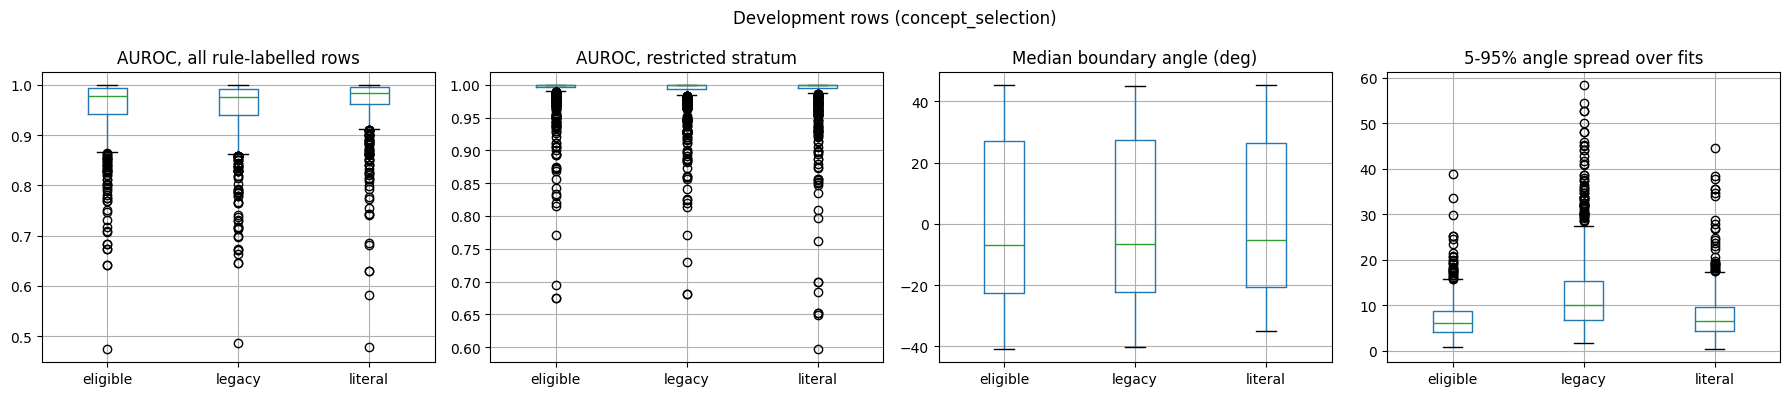

,panel,population,rows,positive_patients,negative_patients
0,auxiliary,all,161.0,16.0,144.0
1,auxiliary,restricted,97.0,16.0,80.0
2,primary,all,157.0,13.0,141.0
3,primary,restricted,91.0,13.0,76.0


In [10]:
def concept_summary(frame, rows_set):
    spread = lambda q: (lambda s: s.quantile(q))
    return (frame.groupby(["build", "reference", "panel", "source", "concept", "pool"])
            .agg(fits=("status", "size"), measured_share=("status", lambda s: (s == "measured").mean()),
                 auroc_all=(f"auroc_all_{rows_set}", "median"), auroc_restricted=(f"auroc_restricted_{rows_set}", "median"),
                 angle_median=(f"angle_{rows_set}", "median"), angle_p05=(f"angle_{rows_set}", spread(0.05)),
                 angle_p95=(f"angle_{rows_set}", spread(0.95)), sensitivity_median=(f"sensitivity_{rows_set}", "median"))
            .reset_index())


def pool_summary(per_concept, cosines):
    by_pool = per_concept.groupby(["panel", "pool"]).agg(
        concepts=("concept", "nunique"), median_auroc_all=("auroc_all", "median"), median_auroc_restricted=("auroc_restricted", "median"),
        median_angle=("angle_median", "median"), median_angle_p05=("angle_p05", "median"), median_angle_p95=("angle_p95", "median"),
        median_measured_share=("measured_share", "median")).reset_index()
    cos = cosines.groupby(["panel", "pool"]).agg(median_fit_cosine=("cosine_median", "median"), q10_fit_cosine=("cosine_q10", "median")).reset_index()
    return by_pool.merge(cos, on=["panel", "pool"])


def pool_plots(per_concept, title, name):
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, column, label in zip(axes[:2], ("auroc_all", "auroc_restricted"), ("all rule-labelled rows", "restricted stratum")):
        per_concept.boxplot(column=column, by="pool", ax=ax); ax.set_title(f"AUROC, {label}"); ax.set_xlabel("")
    per_concept.boxplot(column="angle_median", by="pool", ax=axes[2]); axes[2].set_title("Median boundary angle (deg)"); axes[2].set_xlabel("")
    width = (per_concept.angle_p95 - per_concept.angle_p05).rename("angle_spread").to_frame().assign(pool=per_concept.pool)
    width.boxplot(column="angle_spread", by="pool", ax=axes[3]); axes[3].set_title("5-95% angle spread over fits"); axes[3].set_xlabel("")
    plt.suptitle(title)
    save(fig, name)


development_concepts = concept_summary(fits_df, "selection")
development_summary = pool_summary(development_concepts, cosines_df)
table(development_summary, "development_pool_summary")
table(development_concepts, "development_by_concept", show=False)
if len(join_df):
    saved_anchor = join_df.groupby(["pool"]).agg(median_saved_selection_auroc=("saved_selection_auroc", "median"),
                                                 median_new_selection_auroc=("auroc_restricted_selection", "median"),
                                                 max_gap=("selection_auroc_gap", "max"),
                                                 median_cosine_with_saved=("cosine_with_saved", "median")).reset_index()
    table(saved_anchor, "development_saved_selection_auroc_anchor")
pool_plots(development_concepts, "Development rows (concept_selection)", "step4a_development_pools")
table(populations_df[populations_df.rows_set == "selection"].groupby(["panel", "population"]).agg(
    rows=("rows", "median"), positive_patients=("positive_patients", "median"), negative_patients=("negative_patients", "median")).reset_index(),
      "development_population_counts")

### Step 4b. Evaluation tables (reference-year evaluation rows)

Per-concept median-fit AUROC, boundary angle and sensitivity for each pool and population, with the fitting variability shown as the spread over the 50 fits. Patient intervals use the declared classifiers (fits frozen) with 500 patient draws shared by all pools; the paired pool differences are the difference of per-draw medians over concepts.

,panel,pool,concepts,median_auroc_all,median_auroc_restricted,median_angle,median_angle_p05,median_angle_p95,median_measured_share,median_fit_cosine,q10_fit_cosine
0,auxiliary,eligible,298,0.979357,1.000000,-2.343514,-6.153882,1.723854,1.0,0.991233,0.978110
1,auxiliary,legacy,298,0.978934,1.000000,-2.539479,-8.418418,4.466563,1.0,0.978892,0.946595
2,auxiliary,literal,298,0.984448,1.000000,-0.831960,-5.298021,2.793969,1.0,0.987621,0.971032
3,primary,eligible,470,0.968548,0.998935,-11.484482,-15.892996,-6.405486,1.0,0.985905,0.964923
4,primary,legacy,470,0.964495,0.998424,-10.963215,-21.111922,-1.348737,1.0,0.962654,0.915294
5,primary,literal,470,0.976545,0.998230,-7.013809,-11.594346,-1.918145,1.0,0.979350,0.949329


,panel,population,rows,positive_patients,negative_patients
0,auxiliary,all,322.0,31.0,289.0
1,auxiliary,restricted,197.0,31.0,162.0
2,primary,all,314.0,27.0,283.0
3,primary,restricted,182.0,27.0,152.0


,build,reference,population,pool,comparison,low,high,undefined_fraction
0,all_history,2008,all,legacy,median declared AUROC,0.962613,0.984961,0.0
1,all_history,2008,all,eligible,median declared AUROC,0.962613,0.984961,0.0
2,all_history,2008,all,literal,median declared AUROC,0.967205,0.991162,0.0
3,all_history,2008,all,legacy minus eligible,paired difference of medians,0.000000,0.000000,0.0
4,all_history,2008,all,legacy minus literal,paired difference of medians,-0.012502,0.000624,0.0
...,...,...,...,...,...,...,...,...
127,r1,2007,restricted,eligible,median declared AUROC,0.988510,1.000000,0.0
128,r1,2007,restricted,literal,median declared AUROC,0.986387,0.999260,0.0
129,r1,2007,restricted,legacy minus eligible,paired difference of medians,0.000000,0.000000,0.0
130,r1,2007,restricted,legacy minus literal,paired difference of medians,-0.004285,0.008342,0.0


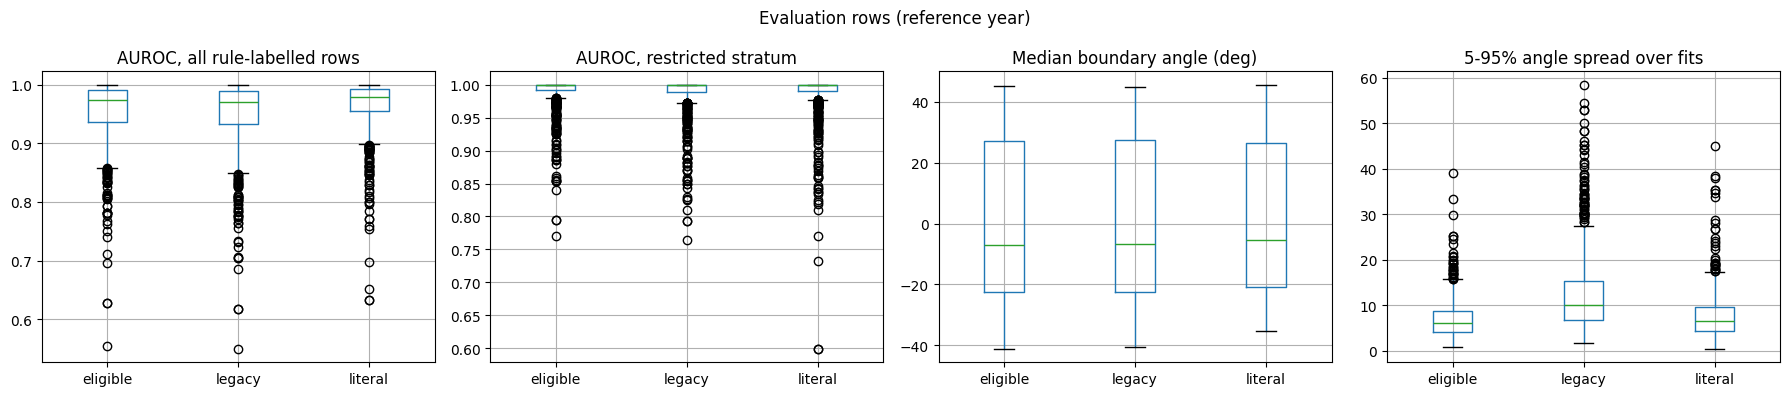

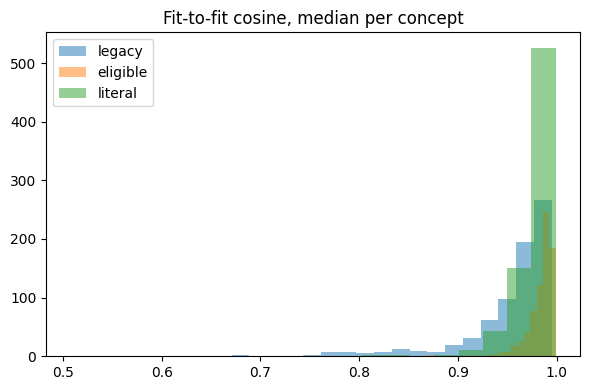

In [11]:
evaluation_concepts = concept_summary(fits_df, "evaluation")
evaluation_summary = pool_summary(evaluation_concepts, cosines_df)
table(evaluation_summary, "evaluation_pool_summary")
table(evaluation_concepts, "evaluation_by_concept", show=False)
table(populations_df[populations_df.rows_set == "evaluation"].groupby(["panel", "population"]).agg(
    rows=("rows", "median"), positive_patients=("positive_patients", "median"), negative_patients=("negative_patients", "median")).reset_index(),
      "evaluation_population_counts")

interval_table = []
for build, reference in sorted({(b, r) for b, r, _, _ in DECLARED_DRAWS}):
    for population in ("all", "restricted"):
        median = {pool: np.nanmedian(np.stack(DECLARED_DRAWS[(build, reference, population, pool)]), axis=0)
                  for pool in POOLS if (build, reference, population, pool) in DECLARED_DRAWS}
        for pool, draws in median.items():
            interval_table.append({"build": build, "reference": reference, "population": population, "pool": pool,
                                   "comparison": "median declared AUROC", **cc.interval(draws)})
        for i, a in enumerate(POOLS):
            for b in POOLS[i + 1:]:
                if a in median and b in median:
                    interval_table.append({"build": build, "reference": reference, "population": population, "pool": f"{a} minus {b}",
                                           "comparison": "paired difference of medians", **cc.interval(median[a] - median[b])})
pool_intervals_df = pd.DataFrame(interval_table)
table(pool_intervals_df, "evaluation_pool_intervals")
pool_plots(evaluation_concepts, "Evaluation rows (reference year)", "step4b_evaluation_pools")

fig, ax = plt.subplots(figsize=(6, 4))
for pool in POOLS:
    values = cosines_df[cosines_df.pool == pool].cosine_median.dropna()
    ax.hist(values, bins=20, alpha=0.5, label=pool)
ax.set_title("Fit-to-fit cosine, median per concept"); ax.legend()
save(fig, "step4_fit_cosines")

## Step 5. Source comparison, with count, capacity and support controls

Every source (and every random draw, and the matched-count pool) uses the identical sweep and tree grid and is capped at the SAE candidate count of its build. Random draws are never pooled; each one is a control. The table gives, per source, the candidates, those with a rule, the distinct rule patient sets, and the distribution of per-candidate held-out quality (rule F1 and tree retained reduction). The exact-duplicate merge and the cross-source Jaccard use the sae, group, pca and random sources (the pool only repeats their candidates), on development rows (`rule_discovery`) and, as a second column, on evaluation rows. No similarity cutoff defines "same concept".

In [12]:
quality = desc_df.set_index("concept")[["rule_f1", "retained_reduction", "tree_f1_cutoff"]]
yield_tables, dev_sets, eval_sets, duplicate_rows, jaccard_rows = [], [], [], [], []
for key in usable():
    st, (build, reference) = STATE[key], key
    data, ref_eval = st["data"], st["ref_eval"]
    results, ruled = [], []
    for src in st["sources"]:
        by_family = {c["family_id"]: c for c in src["concepts"]}
        for candidate in src["candidates"]:
            c = by_family.get(candidate["family_id"])
            dev_patients = set(data["rule_patients"][c["R_rule"]].astype(str)) if c is not None else None
            eval_patients = set(st["patients"]["evaluation"][c["in_R"][ref_eval]]) if c is not None else None
            q = quality.loc[c["concept"]] if c is not None and c["concept"] in quality.index else None
            record = {"id": f"{src['name']}|{candidate['family_id']}", "source": src["name"], "rule_patients": dev_patients,
                      "rule_f1": np.nan if q is None else q.rule_f1, "retained_reduction": np.nan if q is None else q.retained_reduction,
                      "positive_count": candidate["positive_count"], "family_id": candidate["family_id"]}
            results.append(record)
            dev_sets.append({**record, "build": build, "reference": reference})
            eval_sets.append({**record, "rule_patients": eval_patients, "build": build, "reference": reference})
    for metric in ("rule_f1", "retained_reduction"):
        for row in cc.source_yield(results, metric):
            yield_tables.append({"build": build, "reference": reference, "panel": st["panel"], "metric": metric, **row})
    compared = [r for r in results if r["source"] != "pool"]
    for merged in cc.merge_duplicates(compared):
        if len(merged["ids"]) > 1:
            duplicate_rows.append({"build": build, "reference": reference, "ids": json.dumps(merged["ids"]), "sources": json.dumps(merged["sources"]),
                                   "patients": len(merged["patients"])})
    eval_compared = [r for r in eval_sets if r["build"] == build and r["reference"] == reference and r["source"] != "pool"]
    best_dev, best_eval = cc.best_jaccard(compared), cc.best_jaccard(eval_compared)
    for r in compared:
        jaccard_rows.append({"build": build, "reference": reference, "id": r["id"], "source": r["source"], "has_rule": r["rule_patients"] is not None,
                             "best_jaccard_development": best_dev[r["id"]], "best_jaccard_evaluation": best_eval[r["id"]]})

yield_df, duplicates_df, jaccard_df = pd.DataFrame(yield_tables), pd.DataFrame(duplicate_rows), pd.DataFrame(jaccard_rows)
table(yield_df[yield_df.metric == "rule_f1"], "source_yield_rule_f1")
table(yield_df[yield_df.metric == "retained_reduction"], "source_yield_retained_reduction")
table(duplicates_df, "exact_duplicate_rule_sets")
table(jaccard_df.groupby("source").agg(candidates_with_rule=("has_rule", "sum"), median_best_jaccard_development=("best_jaccard_development", "median"),
                                       median_best_jaccard_evaluation=("best_jaccard_evaluation", "median")).reset_index(), "cross_source_jaccard_summary")
table(jaccard_df, "cross_source_jaccard", show=False)

,build,reference,panel,metric,source,candidates,with_rule,distinct_rule_sets,median,q05,q95
0,all_history,2008,primary,rule_f1,sae,9,6,6,0.821449,0.470439,0.916165
1,all_history,2008,primary,rule_f1,group,9,6,6,0.826667,0.653853,0.901647
2,all_history,2008,primary,rule_f1,pca,9,8,8,0.669658,0.491889,0.884909
3,all_history,2008,primary,rule_f1,random1,8,6,6,0.301587,0.161197,0.613333
4,all_history,2008,primary,rule_f1,random2,9,7,7,0.722222,0.268142,0.912059
...,...,...,...,...,...,...,...,...,...,...,...
184,r1,2007,primary,rule_f1,random2,10,6,6,0.724747,0.504032,0.902963
185,r1,2007,primary,rule_f1,random3,8,3,3,0.679245,0.067925,0.806872
186,r1,2007,primary,rule_f1,random4,10,6,6,0.427591,0.220395,0.825000
187,r1,2007,primary,rule_f1,random5,7,2,2,0.337349,0.033735,0.640964


,build,reference,panel,metric,source,candidates,with_rule,distinct_rule_sets,median,q05,q95
9,all_history,2008,primary,retained_reduction,sae,9,6,6,0.784730,0.667332,0.917928
10,all_history,2008,primary,retained_reduction,group,9,6,6,0.779512,0.671897,0.966282
11,all_history,2008,primary,retained_reduction,pca,9,8,8,0.627691,-0.000862,0.958727
12,all_history,2008,primary,retained_reduction,random1,8,6,6,0.779600,-0.711469,0.962613
13,all_history,2008,primary,retained_reduction,random2,9,7,7,0.903413,0.699307,0.971708
...,...,...,...,...,...,...,...,...,...,...,...
193,r1,2007,primary,retained_reduction,random2,10,6,6,0.688686,0.310645,0.946243
194,r1,2007,primary,retained_reduction,random3,8,3,3,0.854993,0.825542,0.884444
195,r1,2007,primary,retained_reduction,random4,10,6,6,0.892237,0.815856,0.956145
196,r1,2007,primary,retained_reduction,random5,7,2,2,0.975725,0.965233,0.986216


,build,reference,ids,sources,patients
0,all_history,2008,"[""group|2008/42/42:279,135:190,215:167"", ""rand...","[""group"", ""random5""]",49
1,all_history,2008,"[""pca|pca/2008/42/1+"", ""random4|random4/2008/4...","[""pca"", ""random4""]",17
2,all_history,2009,"[""sae|2009/42/42:233,135:286,215:138"", ""random...","[""sae"", ""random5""]",7
3,all_history,2009,"[""random3|random3/2009/42/42:38,135:284,215:25...","[""random3"", ""random4""]",19
4,all_history,2009,"[""random4|random4/2009/42/42:1,135:66,215:246""...","[""random4"", ""random4""]",40
5,all_history,2010,"[""group|2010/42/42:73,135:222,215:96"", ""random...","[""group"", ""random3""]",22
6,all_history,2011,"[""sae|2011/42/42:218,135:81,215:139"", ""group|2...","[""sae"", ""group""]",39
7,all_history,2011,"[""sae|2011/42/42:207,135:180,215:36"", ""group|2...","[""sae"", ""group""]",15
8,all_history,2011,"[""sae|2011/42/42:83,135:118,215:10"", ""pca|pca/...","[""sae"", ""pca""]",12
9,all_history,2011,"[""random5|random5/2011/42/42:127,135:110,215:7...","[""random5"", ""random5""]",10


,source,candidates_with_rule,median_best_jaccard_development,median_best_jaccard_evaluation
0,group,107,0.824561,0.826087
1,pca,95,0.723404,0.671233
2,random1,85,0.733333,0.741935
3,random2,73,0.753846,0.736842
4,random3,79,0.708333,0.687500
5,random4,73,0.769231,0.756410
6,random5,65,0.733333,0.714286
7,sae,95,0.833333,0.812500


,build,reference,family_id,rule_f1_group,rule_f1_medoid,rule_f1_difference,retained_reduction_group,retained_reduction_medoid,retained_reduction_difference,jaccard_development,jaccard_evaluation
0,all_history,2008,"2008/42/42:279,135:190,215:167",0.864865,0.885714,-0.020849,0.717243,0.766199,-0.048956,0.938776,0.914286
1,all_history,2008,"2008/42/42:283,135:131,215:29",0.913907,0.756757,0.157151,0.656789,0.929104,-0.272316,0.219512,0.187500
2,all_history,2008,"2008/42/42:0,135:24,215:233",0.616352,0.773333,-0.156981,0.988040,0.644420,0.343620,0.106061,0.132530
3,all_history,2008,"2008/42/42:142,135:265,215:184",0.766355,0.375000,0.391355,0.841782,0.884399,-0.042617,0.163265,0.186047
4,all_history,2008,"2008/42/42:80,135:92,215:154",0.800000,0.869565,-0.069565,0.901008,0.803261,0.097747,0.893617,0.714286
...,...,...,...,...,...,...,...,...,...,...,...
78,last_3,2013,"2013/42/42:21,135:194,215:226",0.166667,0.181818,-0.015152,0.740379,0.683945,0.056435,0.352941,0.375000
79,last_3,2013,"2013/42/42:217,135:101,215:140",0.972477,0.962264,0.010213,0.935084,0.879437,0.055647,1.000000,1.000000
80,last_3,2013,"2013/42/42:80,135:92,215:162",0.296296,0.545455,-0.249158,0.885463,0.911078,-0.025614,0.000000,0.000000
81,r1,2007,"2007/42/42:94,135:3,215:146",0.964286,0.745098,0.219188,0.780814,0.846924,-0.066109,0.736842,0.705882


/tmp/ipykernel_132312/3798299547.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  rank_corr = support.groupby("source").apply(lambda g: pd.Series({"candidates": len(g),


,source,candidates,spearman_rule_f1_vs_support,spearman_retained_reduction_vs_support
0,group,107.0,-0.264741,-0.225175
1,pca,95.0,0.134575,-0.052497
2,pool,96.0,0.187467,-0.068465
3,random1,85.0,0.109452,0.112082
4,random2,73.0,-0.213025,-0.141554
5,random3,79.0,-0.050803,-0.134546
6,random4,73.0,-0.035767,-0.017416
7,random5,65.0,0.036383,-0.389426
8,sae,95.0,-0.078431,-0.186592


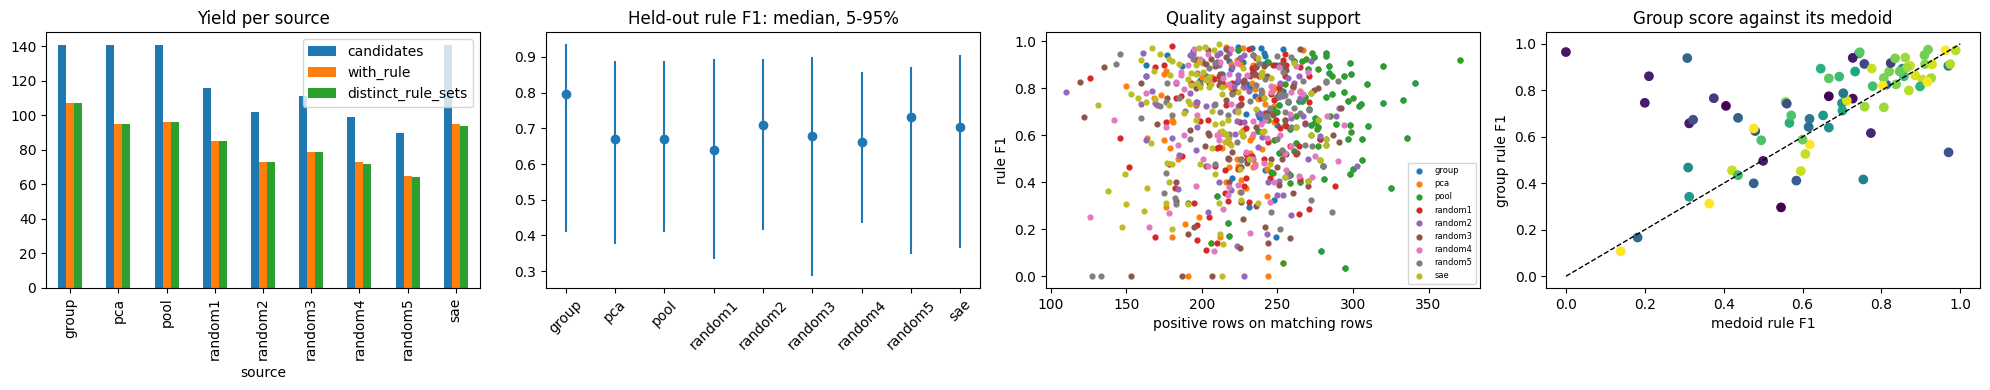

In [13]:
sae_by_family = desc_df[desc_df.source == "sae"].set_index("family_id")
group_pairs = []
for _, g in desc_df[desc_df.source == "group"].iterrows():
    if g.family_id in sae_by_family.index:
        s = sae_by_family.loc[g.family_id]
        j = jaccard_df[jaccard_df.id.isin([f"group|{g.family_id}", f"sae|{g.family_id}"])]
        sets = {r["id"]: r["rule_patients"] for r in dev_sets if r["id"] in (f"group|{g.family_id}", f"sae|{g.family_id}") and r["build"] == g.build}
        evals = {r["id"]: r["rule_patients"] for r in eval_sets if r["id"] in (f"group|{g.family_id}", f"sae|{g.family_id}") and r["build"] == g.build}
        group_pairs.append({"build": g.build, "reference": g.reference, "family_id": g.family_id, "rule_f1_group": g.rule_f1, "rule_f1_medoid": s.rule_f1,
                            "rule_f1_difference": g.rule_f1 - s.rule_f1, "retained_reduction_group": g.retained_reduction,
                            "retained_reduction_medoid": s.retained_reduction, "retained_reduction_difference": g.retained_reduction - s.retained_reduction,
                            "jaccard_development": cc.jaccard(sets[f"group|{g.family_id}"], sets[f"sae|{g.family_id}"]),
                            "jaccard_evaluation": cc.jaccard(evals[f"group|{g.family_id}"], evals[f"sae|{g.family_id}"])})
group_pairs_df = pd.DataFrame(group_pairs)
table(group_pairs_df, "group_score_against_medoid")

support = pd.DataFrame([r for r in dev_sets if r["rule_patients"] is not None])[["source", "positive_count", "rule_f1", "retained_reduction"]]
rank_corr = support.groupby("source").apply(lambda g: pd.Series({"candidates": len(g),
    "spearman_rule_f1_vs_support": g.rule_f1.corr(g.positive_count, method="spearman"),
    "spearman_retained_reduction_vs_support": g.retained_reduction.corr(g.positive_count, method="spearman")})).reset_index()
table(rank_corr, "quality_against_support")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
pivot = yield_df[yield_df.metric == "rule_f1"].groupby("source")[["candidates", "with_rule", "distinct_rule_sets"]].sum()
pivot.plot.bar(ax=axes[0]); axes[0].set_title("Yield per source")
f1 = yield_df[yield_df.metric == "rule_f1"].groupby("source")[["q05", "median", "q95"]].median()
axes[1].errorbar(range(len(f1)), f1["median"], yerr=[f1["median"] - f1.q05, f1.q95 - f1["median"]], fmt="o")
axes[1].set_xticks(range(len(f1))); axes[1].set_xticklabels(f1.index, rotation=45); axes[1].set_title("Held-out rule F1: median, 5-95%")
for name, g in support.groupby("source"):
    axes[2].scatter(g.positive_count, g.rule_f1, s=12, label=name)
axes[2].set_xlabel("positive rows on matching rows"); axes[2].set_ylabel("rule F1"); axes[2].legend(fontsize=6); axes[2].set_title("Quality against support")
if len(group_pairs_df):
    axes[3].scatter(group_pairs_df.rule_f1_medoid, group_pairs_df.rule_f1_group, c=group_pairs_df.jaccard_development, cmap="viridis")
    axes[3].plot([0, 1], [0, 1], "k--", lw=1); axes[3].set_xlabel("medoid rule F1"); axes[3].set_ylabel("group rule F1"); axes[3].set_title("Group score against its medoid")
save(fig, "step5_sources")

## Step 6. Comparison with the historical choices

- frozen rules and masks against the new SAE path (exact anchor, step 1);
- new tree selections against `selected-trees.csv` (model name; descriptive), with the new tuned thresholds;
- saved directions and saved selection AUROCs against the new legacy and eligible fits (descriptive, from step 4);
- the two families whose Idea 2 flag was off.

In [14]:
sae_desc = desc_df[(desc_df.source == "sae") & (desc_df.status == "measured")]
new_trees = {r.concept: f"tree_{int(r.leaves)}" for r in sae_desc.itertuples()}
tree_anchor_row = cc.tree_anchor(new_trees, SELECTED_TREES)
print("tree anchor against selected-trees.csv:", tree_anchor_row)
old_trees = pd.read_csv(SELECTED_TREES)[["concept", "model"]].rename(columns={"model": "model_selected_trees_csv"})
tree_compare = sae_desc[["build", "reference", "concept", "leaves", "tune_mae_tree", "threshold_status", "tuned_threshold", "tree_f2_cutoff", "tree_f2_tuned"]].merge(old_trees, on="concept", how="left")
tree_compare["model_new"] = "tree_" + tree_compare.leaves.astype(int).astype(str)
tree_compare["same_model"] = tree_compare.model_new == tree_compare.model_selected_trees_csv
table(tree_compare, "historical_trees_and_tuned_thresholds")
table(anchors_df, "historical_rule_anchor", show=False)
if len(join_df):
    table(join_df.groupby(["pool", "estimator"]).agg(
        fits=("seed", "size"), failed_new=("failed_new", "sum"), failed_saved=("failed_saved", "sum"),
        median_cosine_with_saved=("cosine_with_saved", "median"), min_cosine_with_saved=("cosine_with_saved", "min"),
        median_selection_auroc_gap=("selection_auroc_gap", "median"), max_selection_auroc_gap=("selection_auroc_gap", "max")).reset_index(),
        "historical_directions_and_selection_auroc")
    table(join_df, "historical_join_by_fit", show=False)

flagged = lambda frame: frame[frame.concept.str.startswith(FLAGGED)]
flagged_rows = {"descriptions": flagged(desc_df), "development": flagged(development_concepts), "evaluation": flagged(evaluation_concepts)}
for name, frame in flagged_rows.items():
    print(f"Idea-flag families, {name}: {len(frame)} rows")
    table(frame, f"idea_flag_families_{name}")

tree anchor against selected-trees.csv: {'compared': 95, 'equal': 95, 'different': 0, 'missing_in_selected': 0}


,build,reference,concept,leaves,tune_mae_tree,threshold_status,tuned_threshold,tree_f2_cutoff,tree_f2_tuned,model_selected_trees_csv,model_new,same_model
0,all_history,2008,"all_history/2008/2008/42/42:283,135:131,215:29",5,0.259991,measured,1.672696,0.000000,0.637255,tree_5,tree_5,True
1,all_history,2008,"all_history/2008/2008/42/42:279,135:190,215:167",5,0.287976,measured,0.619594,0.891892,0.891892,tree_5,tree_5,True
2,all_history,2008,"all_history/2008/2008/42/42:0,135:24,215:233",8,0.153654,measured,1.145496,0.840164,0.840164,tree_8,tree_8,True
3,all_history,2008,"all_history/2008/2008/42/42:80,135:92,215:154",5,0.315847,measured,1.295167,0.864662,0.864662,tree_5,tree_5,True
4,all_history,2008,"all_history/2008/2008/42/42:218,135:228,215:236",8,0.208379,measured,1.481356,0.862745,0.862745,tree_8,tree_8,True
...,...,...,...,...,...,...,...,...,...,...,...,...
90,last_3,2013,"last_3/2013/2013/42/42:132,135:261,215:217",3,0.296708,none,NaN,0.000000,NaN,tree_3,tree_3,True
91,r1,2007,"r1/2007/2007/42/42:94,135:3,215:146",5,0.260957,none,NaN,0.000000,NaN,tree_5,tree_5,True
92,r1,2007,"r1/2007/2007/42/42:65,135:187,215:78",5,0.350007,measured,0.205644,0.337838,0.630499,tree_5,tree_5,True
93,r1,2007,"r1/2007/2007/42/42:268,135:171,215:262",5,0.388021,measured,0.669983,0.000000,0.534351,tree_5,tree_5,True


,pool,estimator,fits,failed_new,failed_saved,median_cosine_with_saved,min_cosine_with_saved,median_selection_auroc_gap,max_selection_auroc_gap
0,eligible,all_negatives,4600,114,114,1.0,1.0,0.0,2.220446e-16
1,legacy,legacy,4600,115,115,1.0,1.0,0.0,2.220446e-16


Idea-flag families, descriptions: 2 rows


,build,reference,panel,source,concept,family_id,cutoff,rule_conditions,rule_count,sweep_tune_f2,...,tree_f2_cutoff,tree_coverage_cutoff,tree_tp_tuned,tree_fp_tuned,tree_fn_tuned,tree_precision_tuned,tree_recall_tuned,tree_f1_tuned,tree_f2_tuned,tree_coverage_tuned
65,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138","2009/42/42:233,135:286,215:138",2.266573,2,1,0.526316,...,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
510,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140","2011/42/42:49,135:91,215:140",1.255998,3,1,0.853659,...,0.941781,0.178344,55.0,1.0,4.0,0.982143,0.932203,0.956522,0.941781,0.178344


Idea-flag families, development: 6 rows


,build,reference,panel,source,concept,pool,fits,measured_share,auroc_all,auroc_restricted,angle_median,angle_p05,angle_p95,sensitivity_median
399,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",eligible,50,0.56,NaN,NaN,-12.758012,-14.594846,-10.028445,NaN
400,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",legacy,50,0.56,NaN,NaN,-14.630588,-35.281642,3.270901,NaN
401,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",literal,50,0.56,NaN,NaN,-9.937211,-12.196949,-7.623639,NaN
1752,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",eligible,50,1.00,0.990587,1.000000,-4.061728,-6.191636,-1.884022,-0.054427
1753,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",legacy,50,1.00,0.991002,1.000000,-3.371318,-7.107722,-0.214593,-0.045531
1754,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",literal,50,1.00,0.992525,0.998557,4.526259,0.993370,6.772309,0.059004


Idea-flag families, evaluation: 6 rows


,build,reference,panel,source,concept,pool,fits,measured_share,auroc_all,auroc_restricted,angle_median,angle_p05,angle_p95,sensitivity_median
399,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",eligible,50,0.56,0.889508,1.0,-12.719265,-14.562335,-9.971739,-0.192773
400,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",legacy,50,0.56,0.867541,1.0,-14.635308,-35.359052,3.354322,-0.217869
401,all_history,2009,primary,sae,"all_history/2009/2009/42/42:233,135:286,215:138",literal,50,0.56,0.925246,1.0,-9.886147,-12.152124,-7.560143,-0.151848
1752,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",eligible,50,1.00,0.997964,1.0,-4.211183,-6.349286,-2.044306,-0.057479
1753,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",legacy,50,1.00,0.997894,1.0,-3.526162,-7.244269,-0.350416,-0.048641
1754,last_3,2011,primary,sae,"last_3/2011/2011/42/42:49,135:91,215:140",literal,50,1.00,0.995437,1.0,4.443178,0.870876,6.683429,0.057229


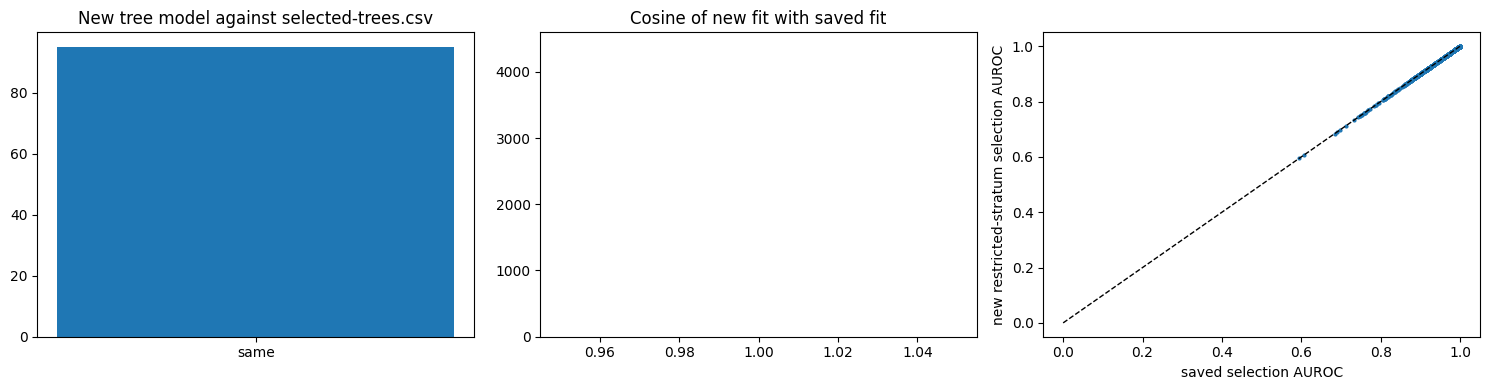

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(tree_compare.same_model.map({True: "same", False: "different"}).value_counts().index,
            tree_compare.same_model.map({True: "same", False: "different"}).value_counts().values)
axes[0].set_title("New tree model against selected-trees.csv")
if len(join_df):
    axes[1].hist(join_df.cosine_with_saved.dropna(), bins=40); axes[1].set_title("Cosine of new fit with saved fit")
    axes[2].scatter(join_df.saved_selection_auroc, join_df.auroc_restricted_selection, s=4)
    axes[2].plot([0, 1], [0, 1], "k--", lw=1); axes[2].set_xlabel("saved selection AUROC"); axes[2].set_ylabel("new restricted-stratum selection AUROC")
save(fig, "step6_historical")

## Step 7. Export and run record

Frozen objects for later work: `bases.npz` (PCA means and axes, random directions, group-score scales), `rules.json`, `trees.pkl` with `tree_leaves.csv`, `cav_classifiers.npz` (declared classifiers in float64, bootstrap coefficients in float32), and `fit_rows.npz` with fitting-row positions in the role arrays (positions only, no patient IDs; this file stays on Fiji). Compact CSV and PNG files are the ones copied locally.

In [16]:
bases_out, rules_out, tree_leaf_rows, trees_out = {}, {}, [], {}
tag = lambda *parts: "|".join(str(p).replace("/", "~") for p in parts)
for key in usable():
    st, (build, reference) = STATE[key], key
    data = st["data"]
    mean, axes_ = cc.pca_axes(data["fit_z"], st["cap"])
    bases_out[tag(build, reference, "pca_mean")], bases_out[tag(build, reference, "pca_axes")] = mean, axes_
    for draw in range(1, RANDOM_DRAWS + 1):
        for s in SAE_SEEDS:
            bases_out[tag(build, reference, "random", draw, s)] = cc.random_directions(data["fit_z"].shape[1], RANDOM_LATENTS, [RANDOM_STREAM, reference, draw, s]).astype(np.float32)
    for info in st["group_info"]:
        bases_out[tag(build, reference, "group_scale", info["id"])] = info["scale"]
        bases_out[tag(build, reference, "group_used", info["id"])] = info["used"]
    for src in st["sources"]:
        for c in src["concepts"]:
            rules_out[c["concept"]] = {"build": build, "reference": reference, "source": src["name"], "family_id": c["family_id"],
                                       "rule": c["rule_dict"], "cutoff": c["cutoff"], "rule_identity": c["rule_identity"], "medoid": c["medoid"]}
for concept, item in PANELS.items():
    trees_out[concept] = item["panel"]["tree"]
    tree_leaf_rows += [{"concept": concept, "source": item["source"], "build": item["build"], **r} for r in cc.leaf_table(item["panel"]["tree"], item["feature_names"])]

classifier_arrays = {}
for concept, item in CLASSIFIERS.items():
    for pool in POOLS:
        classifier_arrays[tag(concept, pool, "coef")] = item[f"{pool}|coefs"].astype(np.float32)
        classifier_arrays[tag(concept, pool, "intercept")] = item[f"{pool}|intercepts"]
        classifier_arrays[tag(concept, pool, "status")] = np.array(item[f"{pool}|statuses"])
        declared = item[f"{pool}|declared"]
        classifier_arrays[tag(concept, pool, "declared_status")] = np.array(declared["status"])
        classifier_arrays[tag(concept, pool, "declared_support")] = np.array(declared["support"])
        if declared["status"] == "measured":
            classifier_arrays[tag(concept, pool, "declared_coef")] = declared["coef"]
            classifier_arrays[tag(concept, pool, "declared_intercept")] = np.array(declared["intercept"])
    classifier_arrays[tag(concept, "seeds")] = np.array(FIT_SEEDS)

np.savez(OUTPUT / "bases.npz", **bases_out)
(OUTPUT / "rules.json").write_text(json.dumps(rules_out, default=str))
with open(OUTPUT / "trees.pkl", "wb") as handle:
    pickle.dump({"sklearn": sklearn.__version__, "trees": trees_out}, handle)
table(pd.DataFrame(tree_leaf_rows), "tree_leaves", show=False)
np.savez(OUTPUT / "cav_classifiers.npz", **classifier_arrays)
private = OUTPUT / "private"
private.mkdir(exist_ok=True)
np.savez(private / "fit_rows.npz", **{tag(b, r, name): (STATE[(b, r)]["bases"]["evaluate"] if name == "evaluation" else STATE[(b, r)]["bases"]["develop"])["row_index"][idx]
                                      for (b, r) in usable() for name, idx in STATE[(b, r)]["rows"].items()})
print("written:", sorted(p.name for p in OUTPUT.iterdir()))

written: ['anchors_exact.csv', 'anchors_replay_by_concept.csv', 'bases.npz', 'candidates.csv', 'candidates_preview.csv', 'cav_classifiers.npz', 'cross_source_jaccard.csv', 'cross_source_jaccard_summary.csv', 'description_intervals.csv', 'descriptions.csv', 'descriptions_by_source.csv', 'development_by_concept.csv', 'development_pool_summary.csv', 'development_population_counts.csv', 'development_saved_selection_auroc_anchor.csv', 'evaluation_by_concept.csv', 'evaluation_pool_intervals.csv', 'evaluation_pool_summary.csv', 'evaluation_population_counts.csv', 'exact_duplicate_rule_sets.csv', 'group_score_against_medoid.csv', 'group_score_member_checks.csv', 'historical_directions_and_selection_auroc.csv', 'historical_join_by_fit.csv', 'historical_rule_anchor.csv', 'historical_trees_and_tuned_thresholds.csv', 'idea_flag_families_descriptions.csv', 'idea_flag_families_development.csv', 'idea_flag_families_evaluation.csv', 'private', 'quality_against_support.csv', 'rules.json', 'run', 'sourc

In [17]:
def sha256(path):
    return hashlib.sha256(open(path, "rb").read()).hexdigest() if os.path.exists(path) else None


run = {"commit": subprocess.run(["git", "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip(),
       "source_sha256": {name: sha256(name) for name in ("concept_candidates.py", "concept_candidates.ipynb")},
       "device": ab.DEVICE, "cuda_available": torch.cuda.is_available(), "sklearn": sklearn.__version__, "workers": WORKERS,
       "builds": [list(b) for b in BUILDS], "builds_used": [list(k) for k in usable()],
       "panels": {f"{b} {r}": STATE[(b, r)]["panel"] for b, r in STATE},
       "split_seed": {f"{b} {r}": STATE[(b, r)].get("split_seed") for b, r in STATE},
       "candidate_cap": {f"{b} {r}": STATE[(b, r)].get("cap") for b, r in STATE},
       "timings_seconds": TIMINGS, "total_seconds": time.time() - STARTED,
       "peak_memory_mb": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024,
       "gpu_per_build": GPU_LOG, "errors": ERRORS, "fit_seeds": [FIT_SEEDS[0], FIT_SEEDS[-1]], "bootstrap_seeds": [cc.BOOTSTRAP_SEEDS[0], cc.BOOTSTRAP_SEEDS[-1]]}
(OUTPUT / "run.json").write_text(json.dumps(run, indent=1, default=str))
print(json.dumps({k: run[k] for k in ("commit", "device", "builds_used", "total_seconds", "peak_memory_mb", "errors")}, indent=1, default=str))

{
 "commit": "16425eebff2d991e6b7cb053c6c17ba4bd3d25bf",
 "device": "cuda",
 "builds_used": [
  [
   "all_history",
   2008
  ],
  [
   "all_history",
   2009
  ],
  [
   "all_history",
   2010
  ],
  [
   "all_history",
   2011
  ],
  [
   "all_history",
   2012
  ],
  [
   "all_history",
   2013
  ],
  [
   "last_3",
   2010
  ],
  [
   "last_3",
   2011
  ],
  [
   "last_3",
   2012
  ],
  [
   "last_3",
   2013
  ],
  [
   "r1",
   2007
  ]
 ],
 "total_seconds": 4290.835369348526,
 "peak_memory_mb": 5744.55078125,
 "errors": []
}
